In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.0){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = paste0(ref, pos, alt)) + 
    geom_line(linewidth = 0.1) + geom_point(size = 0.3) +
    #scale_x_continuous(breaks = 0:16) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Timepoint', y = 'Frequency')
    }

size(4, 8)
options(repr.matrix.max.cols=150)

muts = 2859179
phage = 'JX871397'
chrom = 'U00096'

# Manual modifications
These are very obscure Breseq screw-ups. It's easier to fix them manually.

In [2]:
m_collapsed = read.tsv('../../../datasets/genomics/03_variant_filtering/intermediate/m_collapsed.tsv')

In [3]:
m_manual = 
    m_collapsed %>% 

    filter(
        !(pos == 367843 & ref == 'C'),
        !(pos == 1218203 & alt == 'A'),
        !(pos == 4415889 & type == 'REP')
        ) %>% 

    mutate(
        # 367842
        type = ifelse(pos == 367842, 'DEL', type),
        ref = ifelse(pos == 367842, 'GC', ref),
        pos_end = ifelse(pos == 367842, 367844, pos_end),
        rep_nt = ifelse(pos == 367842, '.', rep_nt),
        delta = ifelse(pos == 367842, -2, delta),
        locus = ifelse(pos == 367842, 'CCCTCTTT.GC.GCGCGCGCG', locus),
        freq = ifelse(pos == 367842 & gen >= 15 & pop == 'E', 1, freq),
        
        # 1218203
        alt = ifelse(pos == 1218203, 'AT', alt),
        delta = ifelse(pos == 1218203, 2, delta),
        freq = ifelse(pos == 1218203 & gen >= 17 & pop == 'F', 1, freq),
        
        # 2826754
        ref = ifelse(pos == 2826754, 'TG', ref),
        alt = ifelse(pos == 2826754, 'CA', alt),
        locus = ifelse(pos == 2826754, 'GTAGTAGG.TG.ATGCGACAC', locus),
        type = ifelse(pos == 2826754, 'SUB', type),
        pos_end = ifelse(pos == 2826754, 2826756, pos_end),
        
        # 4415889
        alt = ifelse(pos == 4415889 & type == 'INS', 'GT', alt),
        freq = ifelse(pos == 4415889 & type == 'INS' & pop == 'E' & gen >= 15, 1, freq),
        
        # 2759336
        alt = ifelse(pos == 2759336, '', alt),
        type = ifelse(pos == 2759336, 'REP', type),
        delta = ifelse(pos == 2759336, -1, delta)
        )

# Update max_f
m_manual =
m_manual %>%
    group_by(pop, chrom, pos, ref, alt) %>%
    mutate(max_f = max(freq)) %>%
    ungroup() %>%
    select(-max_f_vcf)

In [4]:
# Culture E before H takeover (12-13) -> X
pop_X =
m_manual %>%
    filter(pop == 'E') %>% 
    group_by(pop, chrom, pos, ref, alt) %>%
    filter(
        (gen <= 11) |
        (gen == 12 & min(gen[freq == max_f]) <= 12)
        #(gen == 13 & min(gen[freq == max_f]) <= 12)
        ) %>% 
    mutate(pop = 'X', origin = 'X') %>%
    ungroup()

# Culture G before F takeover (13-14) -> Y
pop_Y =
m_manual %>% 
    filter(pop == 'G') %>% 
    group_by(pop, chrom, pos, ref, alt) %>%
    filter(
        (gen <= 12) |
        (gen == 13 & min(gen[freq == max_f]) <= 13)
        #(gen == 14 & min(gen[freq == max_f]) <= 13)
        ) %>% 
    mutate(pop = 'Y', origin = 'Y') %>%
    ungroup()

In H, 4549037 (the fimH V77A mutation) appeared at timepoint 5, where the freq is too high to be from F. But it also appeared at timepoint 6 in F (where it didn't stay long), so it's also present after the contam.

In [5]:
# Culture H before F takeover (5-8) -> Z
pop_Z =
    m_manual %>% 
    filter(pop == 'H') %>% 
    group_by(pop, chrom, pos, ref, alt) %>%
    filter(
        (gen <= 3) |
        (gen %in% 4:8 & min(gen[freq == max_f]) <= 5) |
        (gen <= 8 & pos == 4549037)
        ) %>% 
    mutate(pop = 'Z', origin = 'Z') %>%

    # Correct the frequency to counterbalance the decline
    mutate(
        freq = ifelse(any(gen <= 5 & freq > 0.5) & gen >= 6, 1, freq)
        ) %>% 
    ungroup()

pop_H = 
    m_manual %>% 

    group_by(chrom, pos, ref, alt) %>% 
    mutate(
        origin = ifelse(any(pop == 'F' & gen <= 10), 'F', 'H')
        ) %>% 

    group_by(pop, chrom, pos, ref, alt) %>% 
    filter(
        (pop == 'F' & gen < 4) |
        (pop == 'H' & gen >= 9) |
        (pop == 'H' & gen %in% 4:8 & max(gen[freq == max_f]) >= 7)
        ) %>%

    ungroup() %>% 
    mutate(pop = 'H')

pop_E =
    m_manual %>%
    group_by(pop, chrom, pos, ref, alt) %>%
    filter(
        (pop == 'E' & gen >= 14) |
        (pop == 'E' & gen == 13 & max(gen[freq == max_f]) >= 13)
        ) %>% 
    ungroup() %>% 
    mutate(origin = 'placeholder') %>% 

    # Add the H data prior to 12
    rbind(
        filter(pop_H, gen <= 12)
    ) %>%

    group_by(chrom, pos, ref, alt) %>% 
    mutate(
        origin = case_when(
            any(origin == 'F') ~ 'F',
            any(origin == 'H') ~ 'H',
            T ~ 'E'
            )
        ) %>% 

    mutate(pop = 'E')

pop_G = 
    m_manual %>% 
    group_by(pop, chrom, pos, ref, alt) %>% 
    filter(
        (pop == 'F' & gen <= 13) |
        (pop == 'G' & gen >= 15) |
        (pop == 'G' & gen == 14 & max(gen[freq == max_f]) >= 14)
        ) %>% 

    group_by(chrom, pos, ref, alt) %>% 
    mutate(
        origin = ifelse(any(pop == 'F'), 'F', 'G')
        ) %>% 

    ungroup() %>% 
    mutate(pop = 'G')

pop_other =
    m_manual %>% 
    filter(pop %in% c('A', 'B', 'C', 'D', 'F') | substr(name, 1, 1) == 'I' | substr(name, 1, 1) == 'A') %>% 
    mutate(origin = pop)

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


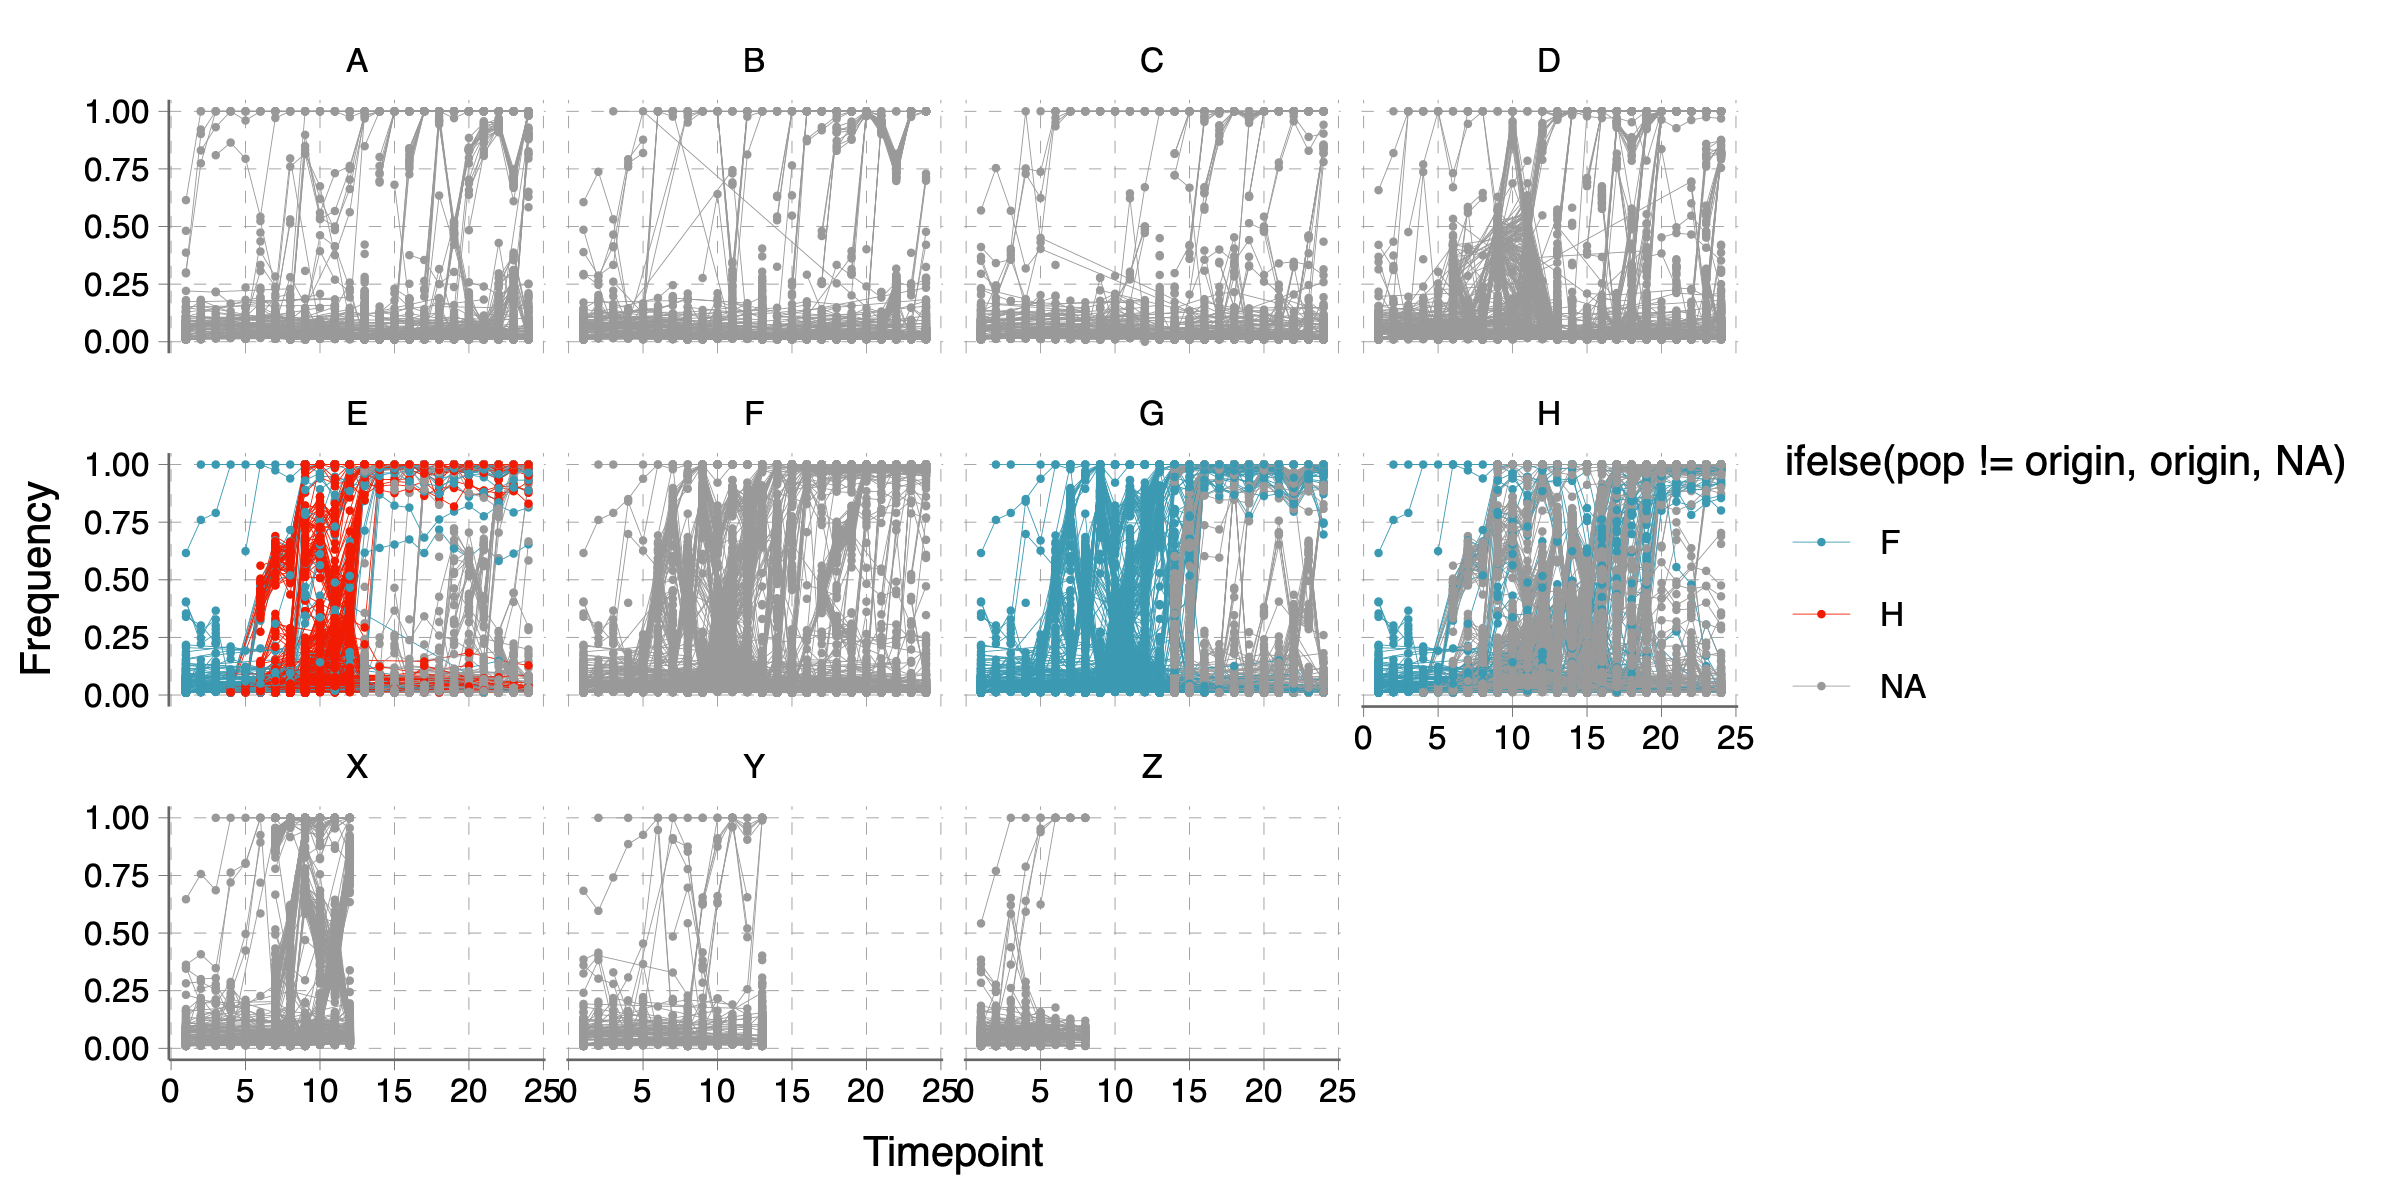

In [6]:
m_perm = 

    # Bind all the pops together
    rbind(
    pop_other,
    pop_X, pop_Y, pop_Z,
    pop_E, pop_G, pop_H
    )

size(4,8)

m_perm %>% filter(gen >= 0) %>% 
freqplot() + aes(col = ifelse(pop != origin, origin, NA))

# Temporary contams
These may have happened during sampling or sequencing prep.

They should be removed to avoid counting as parallel discoveries. In addition, the frequencies of the rest
of the population should be adjusted so the Muller plots add up to 0 (these artificial frequencies don't
have any bearing on the statistical analyses.)

In [7]:
m_temp =
    m_perm %>%
    group_by(pop, chrom, pos, ref, alt) %>% 
    
    # Adjust frequencies for the Muller plots
    mutate(
        # Variants present in B12: to set the B11 freq, interpolate the freq between B10 and B12
        freq = ifelse((name == 'EB11') & any(name == 'EB12' & freq > 0), mean(freq[gen %in% c(10,12)]), freq),
        
        # Variants fixed in B21-B22: set freq to 1 (there's no ambiguity)
        freq = ifelse((name %in% c('EB21', 'EB22')) & freq > 0.5, 1, freq),
        
        # Variants fixed C18: set freq to 1 at C19
        freq = ifelse((name == 'EC19' & freq > 0.9), 1, freq),
        
        # Variants in D6, D9 and D11 reduced by the contam from H6
        freq = ifelse((name == 'ED06') & freq > 0.6 & gen < 15, max(freq), freq),
        freq = ifelse(any(name == 'ED05' & freq > 0.9) & pop == 'D' & gen >= 5 & gen < 15, max(freq), freq),
        freq = ifelse(any(name == 'ED10' & freq > 0.75) & pop == 'D' & gen >= 11 & gen < 15, max(freq), freq),
        
        # Variants fixed in G22: interpolate (lots of pseudo-fixed variants). Contam average freq is 0.072.
        freq = ifelse((name == 'EG22'), ifelse(freq < 1 - 0.072, freq / (1 - 0.072), 1), freq) 

    ) %>%

    # Remove the temporary cross-contams
    group_by(chrom, pos, ref, alt) %>% 
    filter(
        !(any(name == 'ED21') & name %in% c('EB21', 'EB22') & freq < 0.9) &
        !(any(name == 'EA10') & name == 'EB11' & freq < 0.9) &
        !(any(name == 'ED22') & name == 'EG22' & freq < 0.5) &
        !(any(name == 'EG19') & name == 'EC19' & freq < 0.4)
    ) %>%
    ungroup()

In [8]:
# Remove MGEs jumping out of their gene

m_no_mge = m_temp %>% 

    # Remove the jumping MGEs
    filter(delta >= -100)

m_temp %>% filter(delta < -100) %>% write.tsv('../../../datasets/genomics/03_variant_filtering/results/large_deletions.tsv')

Fix sample order.

In [9]:
m_ordered = m_no_mge

# Fix sample order
m_ordered[m_ordered$pop == 'C' & m_ordered$gen == 4, 'gen'] = 99
m_ordered[m_ordered$pop == 'C' & m_ordered$gen == 5, 'gen'] = 4
m_ordered[m_ordered$pop == 'C' & m_ordered$gen == 99, 'gen'] = 5

m_ordered =
m_ordered %>%
    arrange(pop, gen, pos, alt, ref) %>% 
    relocate(name, pop, gen, pos, pos_end, ref, alt, freq) %>% 

    # Correct the names
    mutate(name = paste0('E', pop, sprintf("%02d", gen)))

# Break down apparition waves

Sometimes a variant appears, then disappears for many generations, then comes back.

This could be either a recurring sequencing error, or that the same variant appeared several times in the same population.

**This is important, because if the later is mistaken for the former, then some very important variants will be dismissed as recurring sequencing errors in the downstream mutation filtering!**

Example: **3,035,546 in C:** this is the recurrent *prfB* mutation.

Break down a variant into separate waves if it's absent for >3 timepoints (7,500-10,000 generations) in a row and it reaches some high frequency threshold.

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


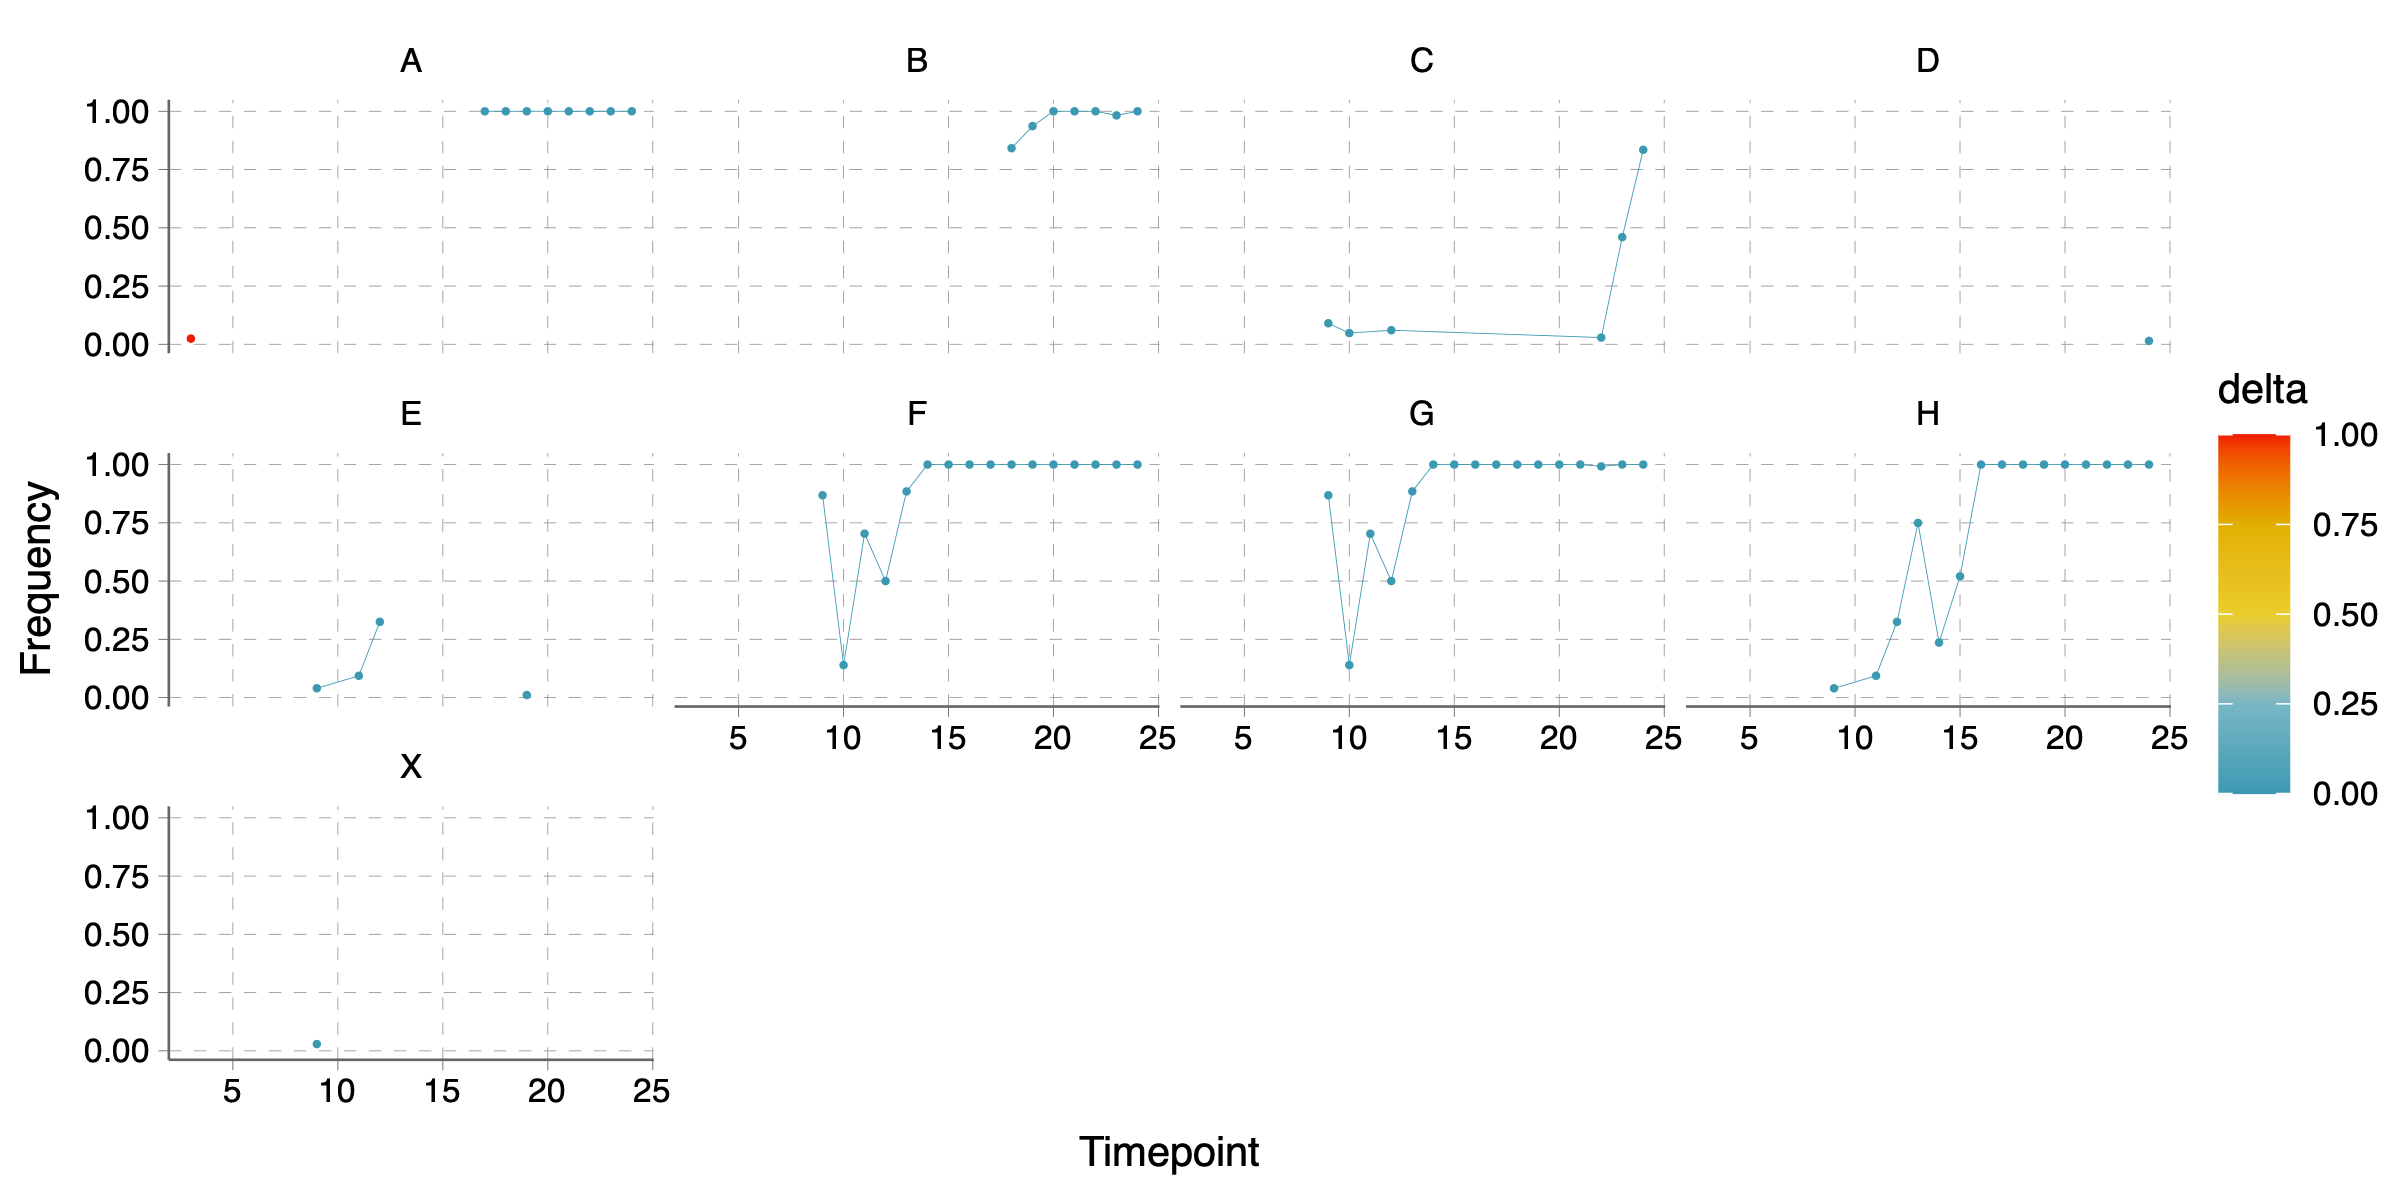

In [10]:
min_wave_separation = 3
freq_thr = 0.5

m_with_waves =
m_ordered %>%

    group_by(chrom, pos, ref, alt) %>% 
    mutate(high_freq = any(freq > freq_thr)) %>% 

    arrange(pop, chrom, pos, ref, alt, gen) %>%
    group_by(pop, chrom, pos, ref, alt) %>%

    mutate(
        wave = ifelse(
            high_freq,
            dense_rank(ifelse(lead(gen, default = 1000) - gen > min_wave_separation, gen, NA)),
            1
        )
    ) %>% 
    fill(wave, .direction = 'up') %>%
    ungroup() %>% 

    select(-high_freq)

# 1879830 in E/H is contradictory if not split in two waves
m_with_waves[m_with_waves$pos == 1879830 & m_with_waves$pop %in% c('E', 'H') & m_with_waves$gen >= 6, 'wave'] = 2

m_with_waves %>% 
filter(abs(pos - 3035546) < 10) %>% 
freqplot() + aes(col = delta)

In [11]:
write.tsv(m_with_waves, '../../../datasets/genomics/03_variant_filtering/intermediate/m_disentangled.tsv')